# Candidate matching in the joint latent space

The tumor-only Leiden labels define the reference subpopulations; each cell
line is represented by the tumor subpopulations among its nearest tumor
neighbors. The primary candidate is the most frequent subpopulation, the
runner-up is the second, and their difference is the margin.

In [1]:
from pathlib import Path
import sys

import anndata as ad
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve()
while not (ROOT / "config" / "config.yaml").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.bio import matching, plots
from src.utils import load_config

cfg = load_config()
paths = cfg["paths"]
bio = cfg.get("bio", {})
FIG_DIR = ROOT / paths["bio"]["figures"]
FIG_DIR.mkdir(parents=True, exist_ok=True)

K_MATCHING = int(bio.get("matching", {}).get("k", 50))
K_SENSITIVITY = list(bio.get("matching", {}).get("k_sensitivity", [15, 50, 100]))
MARGIN = float(bio.get("matching", {}).get("margin", 0.10))

## Matching groups

Tumor cells belong to their tumor-only Leiden subpopulation. Cell line
cells belong to their cell line. The kNN search is restricted to tumor
cells, so a cell line is never its own neighbor.

In [2]:
artifact_path = ROOT / paths["bio"]["joint_artifact"]
combined = ad.read_h5ad(artifact_path)
settings = combined.uns["bio_leiden_settings"]
tumor_res = float(settings["tumor_res"])
leiden_seed = int(settings["leiden_seed"])
tumor_key = f"tumor_leiden_res{tumor_res}"

tumor_mask = combined.obs["dataset"].eq("tumor")
line_mask = combined.obs["dataset"].eq("cell_line")
group = matching.make_match_groups(combined.obs, tumor_key)
combined.obs["match_group"] = group

print(f"artifact: {artifact_path.relative_to(ROOT)}")
print(f"{combined.n_obs:,} cells: {int(tumor_mask.sum()):,} tumor, {int(line_mask.sum()):,} cell line")
print(f"tumor clusters: {combined.obs.loc[tumor_mask, tumor_key].nunique()} at resolution {tumor_res}, seed {leiden_seed}")
print(f"cell lines: {combined.obs.loc[line_mask, 'cell_line'].nunique()}")

artifact: notebooks/4_biological_plausibility/adata_config10_joint/config10_joint_3k.h5ad
110,293 cells: 108,131 tumor, 2,162 cell line
tumor clusters: 18 at resolution 0.9, seed 3
cell lines: 10


## Tumor-only kNN composition

For each cell line cell, the composition is the fraction of its
`K_MATCHING` nearest tumor cells in each subpopulation. The per-cell
table also keeps the nearest distance to every subpopulation.

In [3]:
composition, line_matches, proximity_baseline, tumor_order = matching.match_lines(
    combined.obsm["X_latent"],
    group,
    combined.obs,
    K_MATCHING,
    margin=MARGIN,
)
line_order = matching.line_order(line_matches)
line_composition = (
    composition.groupby("cell_line", observed=True)[tumor_order]
    .mean()
    .loc[line_order]
)

print(f"tumor-tumor q95 baseline: {proximity_baseline:.3f}")
line_composition.round(3)

tumor-tumor q95 baseline: 1.631


,tumor_0,tumor_1,tumor_2,tumor_3,tumor_4,tumor_5,tumor_6,tumor_7,tumor_8,tumor_9,tumor_10,tumor_11,tumor_12,tumor_13,tumor_14,tumor_15,tumor_16,tumor_17
cell_line,,,,,,,,,,,,,,,,,,
HCC56,0.117,0.117,0.0,0.131,0.422,0.143,0.000,0.018,0.000,0.000,0.005,0.000,0.046,0.001,0.0,0.000,0.0,0.0
HT55,0.005,0.065,0.0,0.009,0.517,0.300,0.000,0.003,0.000,0.000,0.000,0.000,0.101,0.000,0.0,0.000,0.0,0.0
LS180,0.036,0.018,0.0,0.025,0.412,0.269,0.002,0.005,0.017,0.023,0.149,0.002,0.038,0.002,0.0,0.000,0.0,0.0
LS1034,0.148,0.085,0.0,0.193,0.267,0.042,0.001,0.033,0.058,0.030,0.037,0.001,0.101,0.004,0.0,0.000,0.0,0.0
CL34,0.003,0.006,0.0,0.010,0.441,0.414,0.000,0.000,0.004,0.010,0.009,0.000,0.101,0.000,0.0,0.000,0.0,0.0
RCM1,0.050,0.067,0.0,0.055,0.241,0.537,0.001,0.001,0.011,0.006,0.000,0.000,0.030,0.000,0.0,0.000,0.0,0.0
CCK81,0.024,0.024,0.0,0.003,0.253,0.517,0.000,0.003,0.001,0.009,0.000,0.000,0.166,0.000,0.0,0.000,0.0,0.0
NCIH747,0.007,0.021,0.0,0.060,0.334,0.466,0.003,0.013,0.014,0.025,0.000,0.000,0.055,0.000,0.0,0.001,0.0,0.0
SNUC4,0.037,0.010,0.0,0.008,0.399,0.418,0.001,0.003,0.007,0.011,0.000,0.000,0.106,0.000,0.0,0.000,0.0,0.0


## Candidate table

`multiple_viable` marks a margin below 0.10. `low_proximity` marks a line
whose median nearest-tumor distance exceeds the tumor-tumor q95 baseline.

In [4]:
line_matches = line_matches.loc[line_order]
line_matches.round(3)

,n_cells,primary_match,primary_frac,second_match,second_frac,margin,multiple_viable,median_dist_nearest_tumor,median_dist_primary,median_dist_second,frac_cells_matched_neighbor,low_proximity
cell_line,,,,,,,,,,,,
HCC56,102,tumor_4,0.422,tumor_5,0.143,0.279,False,1.335,1.533,1.672,0.784,False
HT55,211,tumor_4,0.517,tumor_5,0.300,0.216,False,1.371,1.486,1.646,0.915,False
LS180,362,tumor_4,0.412,tumor_5,0.269,0.143,False,1.112,1.215,1.341,0.796,False
LS1034,153,tumor_4,0.267,tumor_3,0.193,0.073,True,1.124,1.329,1.409,0.575,False
CL34,418,tumor_4,0.441,tumor_5,0.414,0.027,True,1.047,1.157,1.195,0.864,False
RCM1,131,tumor_5,0.537,tumor_4,0.241,0.297,False,1.219,1.310,1.429,0.916,False
CCK81,127,tumor_5,0.517,tumor_4,0.253,0.264,False,1.002,1.096,1.236,0.953,False
NCIH747,80,tumor_5,0.466,tumor_4,0.334,0.132,False,1.140,1.294,1.344,0.888,False
SNUC4,471,tumor_5,0.418,tumor_4,0.399,0.019,True,0.983,1.097,1.150,0.851,False


## Neighborhood-size sensitivity

The candidate identity should not depend on the exact neighborhood size.
`k=50` is the working value; `k=15` and `k=100` are the sensitivity checks.

In [5]:
by_k, k_summary, _ = matching.k_sensitivity(
    combined.obsm["X_latent"],
    group,
    combined.obs,
    K_SENSITIVITY,
    margin=MARGIN,
)
k_table, primary_by_k, k_comparison, k_overview = matching.k_sensitivity_tables(
    by_k, k_summary, reference_k=K_MATCHING
)

print("Candidate matches by k:")
display(k_table.round(3))
print("Primary-match stability:")
display(primary_by_k)
print(f"Sensitivity relative to k={K_MATCHING}:")
display(k_comparison.round(3))
print("Overview by k:")
display(k_overview.round(3))

Candidate matches by k:


,k,cell_line,primary_match,primary_frac,second_match,second_frac,margin,multiple_viable,low_proximity
0,15,SNUC4,tumor_5,0.422,tumor_4,0.400,0.022,True,False
1,15,CL34,tumor_4,0.448,tumor_5,0.412,0.037,True,False
2,15,LS1034,tumor_4,0.279,tumor_3,0.207,0.072,True,False
3,15,LS180,tumor_4,0.418,tumor_5,0.269,0.149,False,False
4,15,NCIH747,tumor_5,0.490,tumor_4,0.318,0.173,False,False
5,15,HT55,tumor_4,0.545,tumor_5,0.288,0.256,False,False
6,15,CCK81,tumor_5,0.511,tumor_4,0.245,0.266,False,False
7,15,HCC56,tumor_4,0.419,tumor_3,0.146,0.273,False,False
8,15,RCM1,tumor_5,0.554,tumor_4,0.230,0.324,False,False
9,15,OUMS23,tumor_6,0.561,tumor_5,0.150,0.412,False,True


Primary-match stability:


k,primary_k15,primary_k50,primary_k100,n_unique_primary,stable_across_all_k
cell_line,,,,,
CCK81,tumor_5,tumor_5,tumor_5,1,True
CL34,tumor_4,tumor_4,tumor_4,1,True
HCC56,tumor_4,tumor_4,tumor_4,1,True
HT55,tumor_4,tumor_4,tumor_4,1,True
LS1034,tumor_4,tumor_4,tumor_4,1,True
LS180,tumor_4,tumor_4,tumor_4,1,True
NCIH747,tumor_5,tumor_5,tumor_5,1,True
OUMS23,tumor_6,tumor_6,tumor_6,1,True
RCM1,tumor_5,tumor_5,tumor_5,1,True


Sensitivity relative to k=50:


,k,cell_line,primary_match,primary_k50,primary_changed_vs_k50,margin,margin_k50,margin_change_vs_k50,multiple_viable,low_proximity
0,15,CCK81,tumor_5,tumor_5,False,0.266,0.264,0.002,False,False
1,15,CL34,tumor_4,tumor_4,False,0.037,0.027,0.010,True,False
2,15,HCC56,tumor_4,tumor_4,False,0.273,0.279,-0.007,False,False
3,15,HT55,tumor_4,tumor_4,False,0.256,0.216,0.040,False,False
4,15,LS1034,tumor_4,tumor_4,False,0.072,0.073,-0.001,True,False
5,15,LS180,tumor_4,tumor_4,False,0.149,0.143,0.006,False,False
6,15,NCIH747,tumor_5,tumor_5,False,0.173,0.132,0.040,False,False
7,15,OUMS23,tumor_6,tumor_6,False,0.412,0.281,0.131,False,True
8,15,RCM1,tumor_5,tumor_5,False,0.324,0.297,0.027,False,False
9,15,SNUC4,tumor_5,tumor_5,False,0.022,0.019,0.003,True,False


Overview by k:


,n_lines,n_multiple_viable,n_low_proximity,median_margin,minimum_margin
k,,,,,
15,10,3,1,0.214,0.022
50,10,3,1,0.180,0.019
100,10,3,1,0.167,0.020


## Distance to each subpopulation

Median nearest-cell Euclidean distance from each cell line to every tumor
subpopulation. The distance heatmap is a supporting view, it does not replace
the composition-based candidate call.

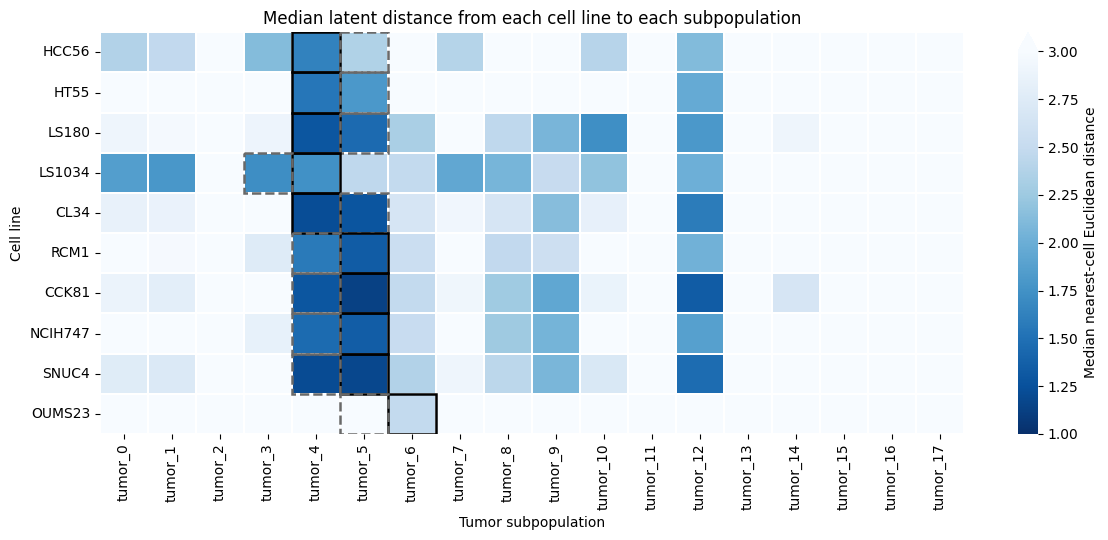

In [6]:
line_distance = matching.subpopulation_distances(
    combined.obsm["X_latent"],
    group,
    combined.obs,
    tumor_order=tumor_order,
    row_order=line_order,
)
plots.plot_distance_heatmap(
    line_distance,
    line_matches,
    FIG_DIR / "bio_line_subpop_distances.png",
)
plt.show()

## Candidate composition and confidence

Left: mean tumor-neighbor composition. Right: primary-minus-runner-up
margin, with the 0.10 threshold. Orange marks ambiguous candidates and
red marks low-proximity lines.

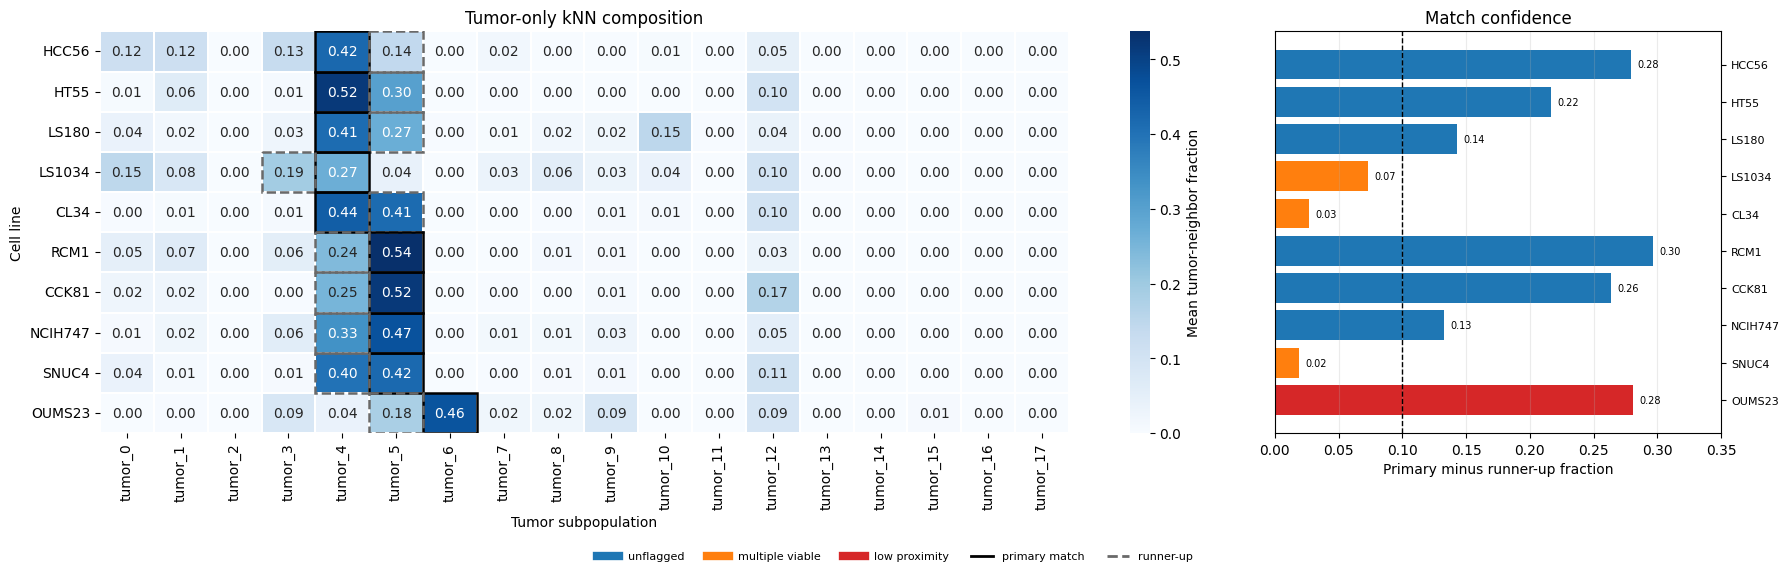

In [7]:
plots.plot_composition_and_margin(
    line_composition,
    line_matches,
    tumor_order,
    line_order,
    FIG_DIR / "bio_matching_confidence.png",
)
plt.show()

## Latent views

The UMAP is a visual check of the frozen artifact, not a matching rule.

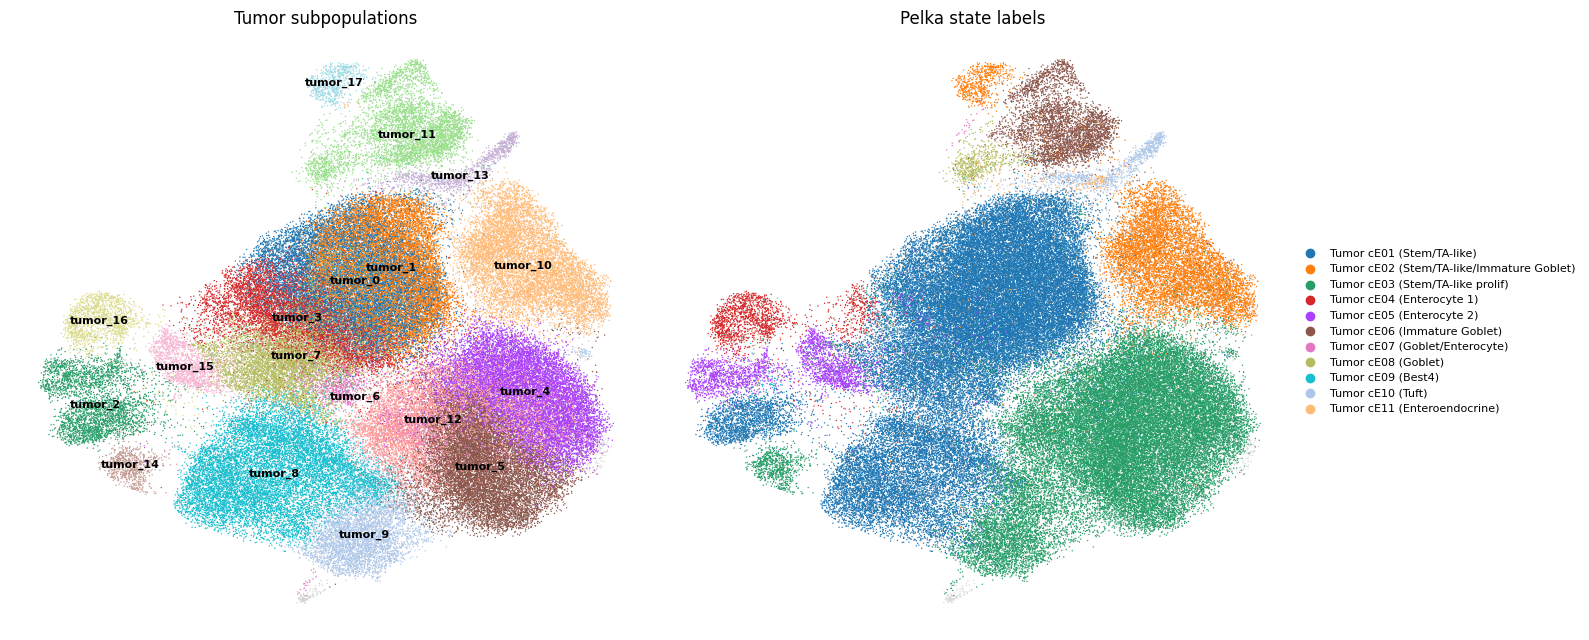

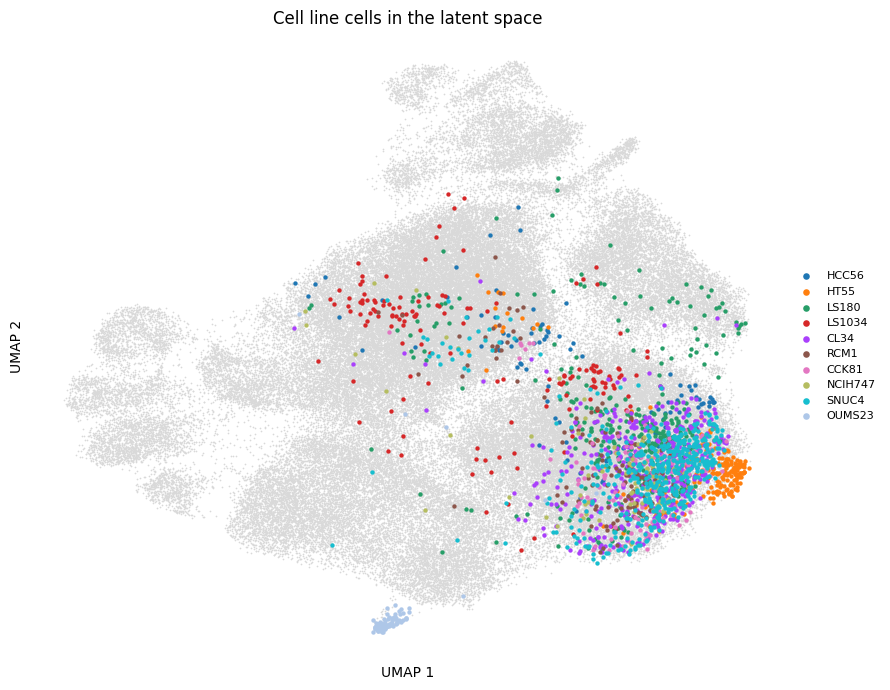

In [8]:
plots.plot_subpopulation_umap(
    combined,
    "match_group",
    "label",
    FIG_DIR / "bio_subpop_umap.png",
    group_order=tumor_order,
)
plt.show()

plots.plot_line_umap(combined, line_order, FIG_DIR / "bio_line_umap.png")
plt.show()